<a href="https://colab.research.google.com/github/banseesiddhapura/banseesiddhapura---programming-and-BDA/blob/main/Copy_of_2_04_Transforms_and_Concatenation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![](https://drive.google.com/uc?export=view&id=1vv_PsWBnUJwSCkwKDoJAC-vXjtaEA4Ts)

# 2.04 Pandas: Transforms and concatenation
### Concatenation
In the previous section we worked with data we created in-session to make two data frames we then merged - joining by columns. In this session we will work in an opposite way: firstly we will read in data from file rather than creating it; then, secondly, we will join datasets via concatenation - joining by rows (shared columns).

To being with we need to access the data. However, we will make things slightly trickier for ourselves by working with an Excel with multiple worksheets. From my.wbs you will find a file called "fake_sales.xlsx". The file contains sales data across three locations (the US, UK and Canada) for January and February (one tab for each month). Save it on your computer.

The first task is to move the file to Colab. Run this code to open a file picker to find the file:

In [ ]:
from google.colab import files
upload = files.upload()

Saving fake_sales (1).xlsx to fake_sales (1).xlsx


We’ll then need to read in this data, and we’ll need to do this one worksheet at a time. Let’s start with January:

In [ ]:
import pandas as pd # if not already done in your session
import numpy as np

jan_df = pd.read_excel('fake_sales.xlsx', sheet_name='January')
jan_df

,Date,US_Sales,UK_Sales,Canada_Sales
0,2024-01-01,9300.52,4270.45,8330.70
1,2024-01-02,6250.65,5680.58,3650.58
2,2024-01-03,6870.29,8380.25,1900.04
3,2024-01-04,5620.17,9420.67,7260.93
4,2024-01-05,9430.28,8640.58,8180.83
5,2024-01-06,9920.03,2150.91,5900.60
6,2024-01-07,7340.07,3810.27,7500.20
7,2024-01-08,3050.27,2060.32,2760.60
8,2024-01-09,6570.98,3270.48,1020.84
9,2024-01-10,1970.04,4520.89,3920.62


As shown, we can inspect the data in full to ensure it has imported correctly. However at 31 rows it starts to become a lot of data to review, and in the realworld its likely our data would be much bigger. Let’s use the _head( )_ function to view just the top five rows:

In [ ]:
jan_df.head()

,Date,US_Sales,UK_Sales,Canada_Sales
0,2024-01-01,9300.52,4270.45,8330.70
1,2024-01-02,6250.65,5680.58,3650.58
2,2024-01-03,6870.29,8380.25,1900.04
3,2024-01-04,5620.17,9420.67,7260.93
4,2024-01-05,9430.28,8640.58,8180.83


Everything looks fine but let's check the data types/dtypes to be sure:

In [ ]:
print(jan_df.dtypes)

Date            datetime64[ns]
US_Sales               float64
UK_Sales               float64
Canada_Sales           float64
dtype: object


Everything looks as expected! Let's do the same for the 'Feb' worksheet.

In [ ]:
feb_df = pd.read_excel('fake_sales.xlsx', sheet_name='February')
feb_df.head()

,Date,US Sales,UK Sales,Canada Sales
0,2024-02-01,8470.48,5170.39,3710.78
1,2024-02-02,4930.76,3320.80,5800.50
2,2024-02-03,6040.84,7310.09,2490.01
3,2024-02-04,6840.61,8980.43,4040.51
4,2024-02-05,4070.03,6360.77,NaN


We now want to join the data. However, unlike in the previous example we don’t want to join as new columns, but as new rows. This means we use a different type of join than the _merge( )_ we did in the previous session. Instead we will use concatenation – i.e. we will add the February rows to the bottom of the January rows. However, we have one small issue – the column names are not exactly the same. The January file, for instance, shows “US_Sales” while the February file has “US Sales”. To join the two we will need to correct this. We do this with the following code:

In [ ]:
feb_df.columns = ['Date', 'US_Sales', 'UK_Sales', 'Canada_Sales']
feb_df.head()

,Date,US_Sales,UK_Sales,Canada_Sales
0,2024-02-01,8470.48,5170.39,3710.78
1,2024-02-02,4930.76,3320.80,5800.50
2,2024-02-03,6040.84,7310.09,2490.01
3,2024-02-04,6840.61,8980.43,4040.51
4,2024-02-05,4070.03,6360.77,NaN


With this change made we can execute the concatenation code. We are using _pd.concat( )_ (pandas' concatenation function, in which we specify the dataframes to join as a list, the axis we want to join (0 for rows (which we want) or 1 for columns) and the type of join. “Left join” and “right join” are not relevant in this case, as we are joining at the bottom not the sides, but we can choose a join of “inner” to ignore columns not in both sets, or “outer” to include all columns irrespective of whether they are in all the Dataframes. Actually in this case it is irrelevant because the columns are both the same.

In [ ]:
sales_df = pd.concat([jan_df, feb_df], axis=0, join='outer')
sales_df.head()

,Date,US_Sales,UK_Sales,Canada_Sales
0,2024-01-01,9300.52,4270.45,8330.70
1,2024-01-02,6250.65,5680.58,3650.58
2,2024-01-03,6870.29,8380.25,1900.04
3,2024-01-04,5620.17,9420.67,7260.93
4,2024-01-05,9430.28,8640.58,8180.83


There are no errors (yay!) but we can only see January data using head - which is unsuprising as our February data is meant to be concatenated to the bottom of the dataframe. Fortunately there is an equivalent function to _head( )_ to show the bottom five records (which should all be February data if everything has worked::

In [ ]:
sales_df.tail()

,Date,US_Sales,UK_Sales,Canada_Sales
23,2024-02-24,1160.20,8500.94,4530.35
24,2024-02-25,2560.97,7350.13,8810.55
25,2024-02-26,8590.08,7320.83,6370.43
26,2024-02-27,4850.27,4870.57,6460.61
27,2024-02-28,8690.32,2350.45,5110.09


### Data Transformations
Data transformations cover a wide range of actions including basic cleaning up steps through to advanced mathematical operations. We'll mostly focus on the former here!

Checking back to the Excel sheet we can see that these are blank cells with no data – missing data, "NaNs" or "nulls" are the common name. We can also verify this issues in pandas using the _isnull( )_ function:

In [ ]:
sales_df.isnull().sum()

,0
Date,0
US_Sales,1
UK_Sales,1
Canada_Sales,2


As we can see there are a total of four null/missing values.

Dealing with missing data is a common problem with no single “right” solution (it depends on the specifics of the case). There is an extensive article on the topic in the pandas documentation (https://pandas.pydata.org/pandas-docs/stable/user_guide/missing_data.html).

In our (fake) scenario, we have followed the most sensible action – we checked with the people who produced the data. They have reported that because of system issues these were actually zero sales days and should be reported as such. We need, therefore to replace the “NaN” records with 0:

In [ ]:
sales_df = sales_df.fillna(0)
sales_df.isnull().sum()

,0
Date,0
US_Sales,0
UK_Sales,0
Canada_Sales,0


The sum of _isnull( )_ is now zero so everthing has worked.

An additional problem is that we have multiple currencies in our dataframe. From the Excel sheet we see that US and Canada are in dollars (presumably US dollars and Canadian dollars respectively), and UK is in pounds. This will prevent us from comparing these values in a meaningful way. We want to convert all of these columns to the same currency – in this case UK pounds. Checking a currency exchange (https://www.xe.com/) we see that a US dollar is worth £0.76, and a Canadian dollar as £0.56. We need to apply these adjustments to our dataframe.

In [ ]:
sales_df['US_Sales'] = sales_df['US_Sales'] * 0.76
sales_df['Canada_Sales'] = sales_df['Canada_Sales'] * 0.56

Finally, what we want to do with this data is to calculate an average by month for each country. We can use pandas’ _groupby( )_ functionality to do this. However, we first need to establish which data is from February and which is from January (obviously it would have been easier to do this before merging, but for the sake of example). We need to create another calculated field, this time capturing the month:

In [ ]:
sales_df['Month'] = pd.DatetimeIndex(sales_df['Date']).month
sales_df.head()

,Date,US_Sales,UK_Sales,Canada_Sales,Month
0,2024-01-01,7068.3952,4270.45,4665.1920,1
1,2024-01-02,4750.4940,5680.58,2044.3248,1
2,2024-01-03,5221.4204,8380.25,1064.0224,1
3,2024-01-04,4271.3292,9420.67,4066.1208,1
4,2024-01-05,7167.0128,8640.58,4581.2648,1


In [ ]:
sales_df.tail()

,Date,US_Sales,UK_Sales,Canada_Sales,Month
23,2024-02-24,881.7520,8500.94,2536.9960,2
24,2024-02-25,1946.3372,7350.13,4933.9080,2
25,2024-02-26,6528.4608,7320.83,3567.4408,2
26,2024-02-27,3686.2052,4870.57,3617.9416,2
27,2024-02-28,6604.6432,2350.45,2861.6504,2


The code creates a new column with a pandas DatetimeIndex (an index number related to an aspect of datatime such as a day of the month would be the number and year would be a number), with the final part specifying we want the month index (1 or 2). Again, we can verify this in the notebook.

This transformation achieves what we need, although maybe not in the prettiest way. To fix this up we will use another transformation to change the month record to "Jan" or "Feb":

In [ ]:
sales_df['Month'] = np.where(sales_df.Month == 1, 'Jan', 'Feb')
sales_df.head()

,Date,US_Sales,UK_Sales,Canada_Sales,Month
0,2024-01-01,7068.3952,4270.45,4665.1920,Jan
1,2024-01-02,4750.4940,5680.58,2044.3248,Jan
2,2024-01-03,5221.4204,8380.25,1064.0224,Jan
3,2024-01-04,4271.3292,9420.67,4066.1208,Jan
4,2024-01-05,7167.0128,8640.58,4581.2648,Jan


In [ ]:
sales_df.tail()

,Date,US_Sales,UK_Sales,Canada_Sales,Month
23,2024-02-24,881.7520,8500.94,2536.9960,Feb
24,2024-02-25,1946.3372,7350.13,4933.9080,Feb
25,2024-02-26,6528.4608,7320.83,3567.4408,Feb
26,2024-02-27,3686.2052,4870.57,3617.9416,Feb
27,2024-02-28,6604.6432,2350.45,2861.6504,Feb


This command uses numpy (np) – specifically the _where( )_ function that works very much like an if condition. We first apply a logical test (does each item in the "Month" column equal 1) and if True we change it to "Jan" and if False we change it to "Feb". Again this is not necessarily the most efficient way to achieve what we want but it does show some useful functionality.

Finally we do our groupings. We will group by month to get the figures for each region. However, as we aggregate the figures we need to pick an appropriate method. This could be the maximum, the minimum, the median, or so on. In this case we will use the mean average:

In [ ]:
sales_group_df = sales_df.groupby(['Month']).mean()
sales_group_df

,Date,US_Sales,UK_Sales,Canada_Sales
Month,,,,
Feb,2024-02-14 12:00:00,4022.115157,5219.794286,3018.013400
Jan,2024-01-16 00:00:00,4340.950839,5101.150000,2650.518658


As can be seen we now have aggregated/average sales for each day of each month for each of our regions. Good job!

### EXERCISE
1) Re-do the last steps of the sales group process changing the _groupby( )_ function for sales figures to _median( )_ ... what difference does this make to the result? Would this be expected?



In [ ]:
sales_group_median_df = sales_df.groupby(['Month']).median()
display(sales_group_median_df)

By using median you find the middle value for each country in the each month rather than the average. The difference is expected as the middle value has a high chance of being an extreme outlier whereas the mean averages out all those extreme values. If the sales are symmetric the mean and median would be close.

### More groupby Options
We use the groupby function when we want to change the unit of aggregation of a DataFrame. For instance, we may have a DataFrame that has 1x row per day and we want to aggregate up to 1x row per month:

In [ ]:
import pandas as pd
df = pd.DataFrame({"Team": ["DS", "DT", "DT", "DS", "DS"], "salary": [100000, 100, 20000, 0, 100000]})
print("Raw Data")
print(df)
print("\n")

# team based aggregation (average)
# remove levels means we convert the output to a flat 2D shape rather than leaving a gap
mean_df = df.groupby(['Team']).mean().reset_index()

print("Aggregation by Mean")
print(mean_df)
print("\n")

# team based aggregation (sum)
sum_df = df.groupby(['Team']).sum().reset_index()

print("Aggregation by Sum")
print(sum_df)
print("\n")

# team based aggregation (median)
median_df = df.groupby(['Team']).median().reset_index()

print("Aggregation by Median")
print(median_df)
print("\n")

# team based aggregation (maximum)
max_df = df.groupby(['Team']).max().reset_index()

print("Aggregation by Maximum")
print(max_df)
print("\n")

Raw Data
  Team  salary
0   DS  100000
1   DT     100
2   DT   20000
3   DS       0
4   DS  100000


Aggregation by Mean
  Team        salary
0   DS  66666.666667
1   DT  10050.000000


Aggregation by Sum
  Team  salary
0   DS  200000
1   DT   20100


Aggregation by Median
  Team    salary
0   DS  100000.0
1   DT   10050.0


Aggregation by Maximum
  Team  salary
0   DS  100000
1   DT   20000




### Time and Date
In this last part we will use pandas' date/time functionality for data  transforms:

In [ ]:
df = pd.DataFrame({"id": [3, 1, 2, 4, 10], "salary": [100000, 100, 20000, 0, 100000],
                   "dob": ["10/01/1950", "01/01/1990", "01/01/1980", "12/12/1981", "13/06/1981"]})
print(df)

# convert a column which has a date stored as string, into a column
# stored as date. dayfirst=True means we use the UK style of date
# (DDMMYYYY) rather than US (MMDDYYYY)
df['dob'] = pd.to_datetime(df['dob'], dayfirst=True)

# from a date object create cols for year, month, day, hour and minute
df['Year'] =  pd.DatetimeIndex(df['dob']).year
df['Month'] = pd.DatetimeIndex(df['dob']).month
df['Day'] = pd.DatetimeIndex(df['dob']).day
df['Hour'] = pd.DatetimeIndex(df['dob']).hour
df['Minute'] = pd.DatetimeIndex(df['dob']).minute

print("\n")
print(df)

# work out age by substracting the DOB from the date today
# note this is much harder than you may think it would be because years
# are different lengths and so ambiguous
df["Age"] = pd.to_datetime("today", dayfirst=True)-df['dob']
df["Age"] = round(df.Age.dt.days / 365, 1)

print("\n")
print(df)

   id  salary         dob
0   3  100000  10/01/1950
1   1     100  01/01/1990
2   2   20000  01/01/1980
3   4       0  12/12/1981
4  10  100000  13/06/1981


   id  salary        dob  Year  Month  Day  Hour  Minute
0   3  100000 1950-01-10  1950      1   10     0       0
1   1     100 1990-01-01  1990      1    1     0       0
2   2   20000 1980-01-01  1980      1    1     0       0
3   4       0 1981-12-12  1981     12   12     0       0
4  10  100000 1981-06-13  1981      6   13     0       0


   id  salary        dob  Year  Month  Day  Hour  Minute   Age
0   3  100000 1950-01-10  1950      1   10     0       0  75.8
1   1     100 1990-01-01  1990      1    1     0       0  35.8
2   2   20000 1980-01-01  1980      1    1     0       0  45.8
3   4       0 1981-12-12  1981     12   12     0       0  43.9
4  10  100000 1981-06-13  1981      6   13     0       0  44.4


As an additional example:

In [ ]:
df = pd.DataFrame({"student": [1, 2, 3, 4, 5],
                   "deadline": ["01/11/2025", "02/11/2025", "03/11/2025", "04/11/2025", "05/11/2025"],
                   "submission": ["01/11/2025", "01/11/2025", "02/12/2025", "03/11/2025", "01/12/2025"]})

df.head()

,student,deadline,submission
0,1,01/11/2025,01/11/2025
1,2,02/11/2025,01/11/2025
2,3,03/11/2025,02/12/2025
3,4,04/11/2025,03/11/2025
4,5,05/11/2025,01/12/2025


In [ ]:
# convert a column which has a date stored as string, into a column
# stored as date. dayfirst=True means we use the UK style of date
# (DDMMYYYY) rather than US (MMDDYYYY)
# but this time inside a for loop

date_cols = ["deadline", "submission"]

for col in date_cols:
  df[col] = pd.to_datetime(df[col], dayfirst=True)

df.head()

,student,deadline,submission
0,1,2025-11-01,2025-11-01
1,2,2025-11-02,2025-11-01
2,3,2025-11-03,2025-12-02
3,4,2025-11-04,2025-11-03
4,5,2025-11-05,2025-12-01


Now let's look at when students submitted vs deadline:

In [ ]:
df["after_deadline"] = df["submission"] - df["deadline"]
df.head()

,student,deadline,submission,after_deadline
0,1,2025-11-01,2025-11-01,0 days
1,2,2025-11-02,2025-11-01,-1 days
2,3,2025-11-03,2025-12-02,29 days
3,4,2025-11-04,2025-11-03,-1 days
4,5,2025-11-05,2025-12-01,26 days


__PUBLIC SERVICE ANNOUNCEMENT__: Don't submit after the deadline ... it's very expensive.

__EXERCISES__:
Play around with Colab\'s "_Generate code with df_" functionality. Try asking for new data items or charts. Before you run the code, think about what you would expect to happen and see if it does!

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load a sample public Spotify dataset from GitHub
spotify_url = 'https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-01-21/spotify_songs.csv'
spotify_df = pd.read_csv(spotify_url)

# 1. Structure of the data
print("--- Dataset Shape ---")
print(spotify_df.shape)
print("\n--- Dataset Columns and Types ---")
spotify_df.info()

--- Dataset Shape ---
(32833, 23)

--- Dataset Columns and Types ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32833 entries, 0 to 32832
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   track_id                  32833 non-null  object 
 1   track_name                32828 non-null  object 
 2   track_artist              32828 non-null  object 
 3   track_popularity          32833 non-null  int64  
 4   track_album_id            32833 non-null  object 
 5   track_album_name          32828 non-null  object 
 6   track_album_release_date  32833 non-null  object 
 7   playlist_name             32833 non-null  object 
 8   playlist_id               32833 non-null  object 
 9   playlist_genre            32833 non-null  object 
 10  playlist_subgenre         32833 non-null  object 
 11  danceability              32833 non-null  float64
 12  energy                    32833 non-null  float

In [ ]:
print("\n--- Descriptive Statistics ---")
display(spotify_df.describe())

# Check for missing values
print("\n--- Missing Values ---")
print(spotify_df.isnull().sum()[spotify_df.isnull().sum() > 0])


--- Descriptive Statistics ---


,track_popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
count,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000
mean,42.477081,0.654850,0.698619,5.374471,-6.719499,0.565711,0.107068,0.175334,0.084747,0.190176,0.510561,120.881132,225799.811622
std,24.984074,0.145085,0.180910,3.611657,2.988436,0.495671,0.101314,0.219633,0.224230,0.154317,0.233146,26.903624,59834.006182
min,0.000000,0.000000,0.000175,0.000000,-46.448000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4000.000000
25%,24.000000,0.563000,0.581000,2.000000,-8.171000,0.000000,0.041000,0.015100,0.000000,0.092700,0.331000,99.960000,187819.000000
50%,45.000000,0.672000,0.721000,6.000000,-6.166000,1.000000,0.062500,0.080400,0.000016,0.127000,0.512000,121.984000,216000.000000
75%,62.000000,0.761000,0.840000,9.000000,-4.645000,1.000000,0.132000,0.255000,0.004830,0.248000,0.693000,133.918000,253585.000000
max,100.000000,0.983000,1.000000,11.000000,1.275000,1.000000,0.918000,0.994000,0.994000,0.996000,0.991000,239.440000,517810.000000



--- Missing Values ---
track_name          5
track_artist        5
track_album_name    5
dtype: int64


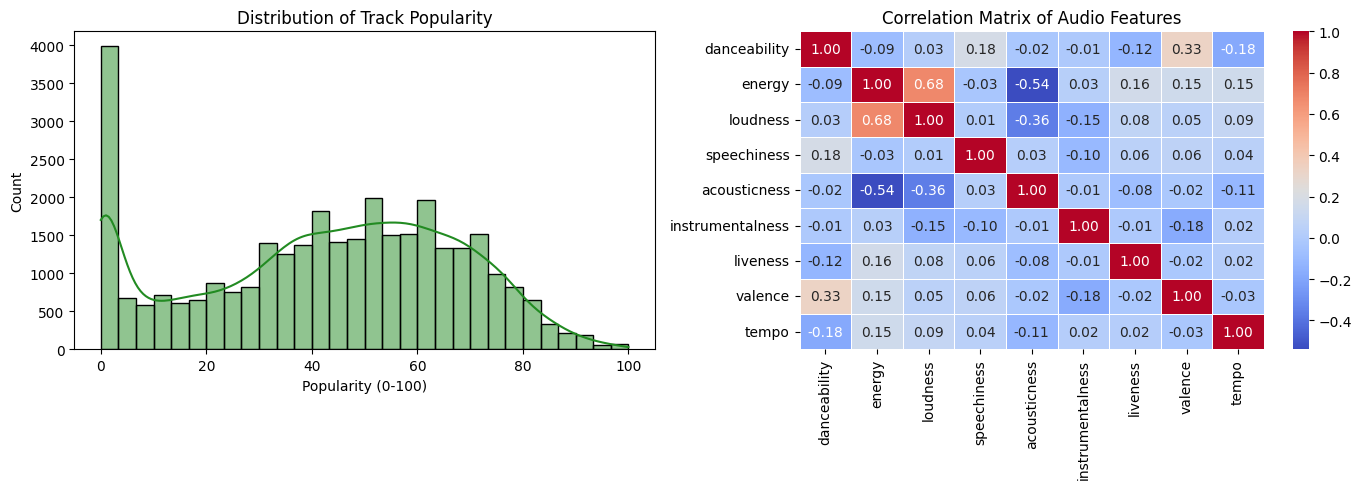

In [ ]:
plt.figure(figsize=(14, 5))

# Subplot 1: Distribution of Track Popularity
plt.subplot(1, 2, 1)
sns.histplot(spotify_df['track_popularity'], bins=30, kde=True, color='forestgreen')
plt.title('Distribution of Track Popularity')
plt.xlabel('Popularity (0-100)')
plt.ylabel('Count')

# Subplot 2: Correlation Heatmap of Audio Features
plt.subplot(1, 2, 2)
features = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']
correlation_matrix = spotify_df[features].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Audio Features')

plt.tight_layout()
plt.show()